In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def _sample_sigma(rng, sigma_or_range):
    if isinstance(sigma_or_range, (tuple, list, np.ndarray)):
        return rng.uniform(float(sigma_or_range[0]), float(sigma_or_range[1]))
    return float(sigma_or_range)


def _sample_duration_perturbation(rng, std, lower=-0.95):
    for _ in range(100):
        x = rng.normal(0.0, std)
        if x > lower:
            return x
    return lower


def _check_positive_int(name, value, allow_zero=False):
    if allow_zero:
        if not isinstance(value, int) or value < 0:
            raise ValueError(f"{name} must be a nonnegative integer.")
    else:
        if not isinstance(value, int) or value <= 0:
            raise ValueError(f"{name} must be a positive integer.")


# Training workload

def training_phase(
    T=10.0,
    Fs=100,
    F=(0.5, 1.5),
    up_ratio=(0.55, 0.80),
    p_hat_tr=1.0,
    sigma_xi=0.1,
    sigma_delta=0.05,
    mu_delta=0.3,
    sigma_eta_up=(0.02, 0.05),
    sigma_eta_down=(0.01, 0.03),
    seed=None,
    return_info=False,
):

    _check_positive_int("Fs", Fs)

    rng = np.random.default_rng(seed)
    N = int(round(T * Fs))

    if N <= 0:
        raise ValueError("T * Fs must be positive.")

    power = np.zeros(N)

    f0 = rng.uniform(*F)

    sig_eta_up = _sample_sigma(rng, sigma_eta_up)
    sig_eta_down = _sample_sigma(rng, sigma_eta_down)

    cycle_info = []
    i = 0

    while i < N:
        xi_i = _sample_duration_perturbation(rng, sigma_xi)

        T_cycle = 1.0 / (f0 * (1.0 + xi_i))
        n_cycle = max(2, int(round(T_cycle * Fs)))

        r_i = rng.uniform(*up_ratio)

        n_up = int(round(r_i * n_cycle))
        n_up = min(max(1, n_up), n_cycle - 1)
        n_down = n_cycle - n_up

        cycle_start_idx = i

        len_up = min(n_up, N - i)

        delta_up_i = rng.normal(0.0, sigma_delta)
        eta_up = rng.normal(0.0, sig_eta_up, len_up)

        power[i:i + len_up] = p_hat_tr * (1.0 + delta_up_i + eta_up)
        i += len_up

        if i >= N:
            cycle_info.append(
                {
                    "cycle_start_idx": cycle_start_idx,
                    "xi": xi_i,
                    "r": r_i,
                    "n_up": len_up,
                    "n_down": 0,
                    "delta_up": delta_up_i,
                    "delta_down": None,
                }
            )
            break

        len_down = min(n_down, N - i)

        delta_down_i = rng.normal(mu_delta, sigma_delta)
        eta_down = rng.normal(0.0, sig_eta_down, len_down)

        power[i:i + len_down] = p_hat_tr * (1.0 - delta_down_i + eta_down)
        i += len_down

        cycle_info.append(
            {
                "cycle_start_idx": cycle_start_idx,
                "xi": xi_i,
                "r": r_i,
                "n_up": len_up,
                "n_down": len_down,
                "delta_up": delta_up_i,
                "delta_down": delta_down_i,
            }
        )

    power = np.clip(power, 0.0, None)

    if return_info:
        info = {
            "f0": f0,
            "sigma_eta_up": sig_eta_up,
            "sigma_eta_down": sig_eta_down,
            "cycle_info": cycle_info,
        }
        return power, info

    return power


def finetuning_phase(
    T=10.0,
    Fs=100,
    F=(0.3, 0.7),
    tail_ratio=(0.70, 0.90),
    p_hat_ft=1.0,
    sigma_zeta=0.1,
    sigma_delta=0.03,
    mu_delta=0.8,
    sigma_eta_tail=(0.01, 0.03),
    sigma_eta_idle=(0.005, 0.02),
    seed=None,
    return_info=False,
):

    _check_positive_int("Fs", Fs)

    rng = np.random.default_rng(seed)
    N = int(round(T * Fs))

    if N <= 0:
        raise ValueError("T * Fs must be positive.")

    power = np.zeros(N)

    f1 = rng.uniform(*F)

    sig_eta_tail = _sample_sigma(rng, sigma_eta_tail)
    sig_eta_idle = _sample_sigma(rng, sigma_eta_idle)

    cycle_info = []
    i = 0

    while i < N:
        zeta_i = _sample_duration_perturbation(rng, sigma_zeta)

        T_cycle = 1.0 / (f1 * (1.0 + zeta_i))
        n_cycle = max(2, int(round(T_cycle * Fs)))

        r_i = rng.uniform(*tail_ratio)

        n_tail = int(round(r_i * n_cycle))
        n_tail = min(max(1, n_tail), n_cycle - 1)
        n_idle = n_cycle - n_tail

        cycle_start_idx = i

        len_tail = min(n_tail, N - i)

        delta_tail_i = rng.normal(0.0, sigma_delta)
        eta_tail = rng.normal(0.0, sig_eta_tail, len_tail)

        power[i:i + len_tail] = p_hat_ft * (1.0 + delta_tail_i + eta_tail)
        i += len_tail

        if i >= N:
            cycle_info.append(
                {
                    "cycle_start_idx": cycle_start_idx,
                    "zeta": zeta_i,
                    "r": r_i,
                    "n_tail": len_tail,
                    "n_idle": 0,
                    "delta_tail": delta_tail_i,
                    "delta_idle": None,
                }
            )
            break

        len_idle = min(n_idle, N - i)

        delta_idle_i = rng.normal(mu_delta, sigma_delta)
        eta_idle = rng.normal(0.0, sig_eta_idle, len_idle)

        power[i:i + len_idle] = p_hat_ft * (1.0 - delta_idle_i + eta_idle)
        i += len_idle

        cycle_info.append(
            {
                "cycle_start_idx": cycle_start_idx,
                "zeta": zeta_i,
                "r": r_i,
                "n_tail": len_tail,
                "n_idle": len_idle,
                "delta_tail": delta_tail_i,
                "delta_idle": delta_idle_i,
            }
        )

    power = np.clip(power, 0.0, None)

    if return_info:
        info = {
            "f1": f1,
            "sigma_eta_tail": sig_eta_tail,
            "sigma_eta_idle": sig_eta_idle,
            "cycle_info": cycle_info,
        }
        return power, info

    return power

In [3]:
def _resolve_workload_schedule(schedule, T, rng):
    """Resolve workload timing and ramp-rate parameters.

    Turn-on options
    ---------------
    1) Fixed start:
       schedule = {
           "turn_on_mode": "fixed",
           "turn_on_time": 1.2,
           ...
       }

    2) Random start within a user-defined boundary:
       schedule = {
           "turn_on_mode": "random",
           "turn_on_range": (0.5, 2.0),
           ...
       }
       The turn-on time is sampled uniformly from this interval.

    Duration
    --------
    duration [s] is the total active workload duration measured from turn-on
    until the workload becomes exactly zero. Thus

        turn_off_time = turn_on_time + duration.

    The user does not specify turn_off_time directly.

    Ramp limits
    -----------
    ramp_up_ratio, ramp_down_ratio [1/s]
        Boundary ramp-rate limits for workload turn-on and turn-off.

    periodic_ramp_up_ratio, periodic_ramp_down_ratio [1/s]
        Internal ramp-rate limits applied at every periodic low->high and
        high->low workload-state transition, respectively.

    All ratios are normalized by the nominal power of the individual workload.
    """
    T = float(T)
    if schedule is None:
        schedule = {
            "turn_on_mode": "fixed",
            "turn_on_time": 0.0,
            "duration": T,
        }
    if not isinstance(schedule, dict):
        raise TypeError("schedule must be a dictionary or None.")
    if "turn_off_time" in schedule:
        raise ValueError(
            "turn_off_time is no longer a user parameter. "
            "Specify duration instead; turn_off_time is computed as "
            "turn_on_time + duration."
        )

    mode = str(schedule.get("turn_on_mode", "random")).lower()
    if mode not in ("fixed", "random"):
        raise ValueError("turn_on_mode must be either 'fixed' or 'random'.")

    duration_raw = schedule.get("duration", None)

    if mode == "fixed":
        if "turn_on_time" not in schedule:
            raise ValueError(
                "turn_on_time must be provided when turn_on_mode='fixed'."
            )
        turn_on_time = float(schedule["turn_on_time"])
        if not (0.0 <= turn_on_time < T):
            raise ValueError("turn_on_time must satisfy 0 <= turn_on_time < T.")

        duration = T - turn_on_time if duration_raw is None else float(duration_raw)

    else:  # random
        if "turn_on_range" not in schedule:
            raise ValueError(
                "turn_on_range must be provided when turn_on_mode='random'."
            )
        turn_on_range = schedule["turn_on_range"]
        if not isinstance(turn_on_range, (tuple, list, np.ndarray)) or len(turn_on_range) != 2:
            raise ValueError("turn_on_range must be a two-element (min, max) interval.")

        t_lo = float(turn_on_range[0])
        t_hi = float(turn_on_range[1])
        if not (0.0 <= t_lo <= t_hi <= T):
            raise ValueError("turn_on_range must satisfy 0 <= min <= max <= T.")

        if duration_raw is None:
            raise ValueError(
                "duration must be provided when turn_on_mode='random'."
            )

        duration = float(duration_raw)
        if duration <= 0.0:
            raise ValueError("duration must be positive.")

        # Sample from exactly the user-specified interval. No max_start_time
        # or implicit shrinking of the interval is used.
        if t_hi + duration > T + 1e-12:
            raise ValueError(
                "turn_on_range upper bound + duration must not exceed T."
            )
        turn_on_time = rng.uniform(t_lo, t_hi) if t_hi > t_lo else t_lo

    if duration <= 0.0:
        raise ValueError("duration must be positive.")

    turn_off_time = turn_on_time + duration
    if turn_off_time > T + 1e-12:
        raise ValueError(
            "turn_on_time + duration must not exceed the simulation horizon T."
        )
    turn_off_time = min(turn_off_time, T)

    ramp_names = (
        "ramp_up_ratio",
        "ramp_down_ratio",
        "periodic_ramp_up_ratio",
        "periodic_ramp_down_ratio",
    )
    ramp_values = {
        name: float(schedule.get(name, np.inf))
        for name in ramp_names
    }
    for name, value in ramp_values.items():
        if not (np.isinf(value) or value > 0.0):
            raise ValueError(f"{name} must be positive or np.inf.")

    return {
        "turn_on_mode": mode,
        "turn_on_time": turn_on_time,
        "turn_off_time": turn_off_time,
        "duration": duration,
        **ramp_values,
    }


def _extract_periodic_boundaries(active_info, M):
    """Return internal state-transition boundaries as (index, direction).

    direction='down' means high-load -> low-load.
    direction='up' means low-load -> next high-load.

    The initial activation at index 0 is intentionally excluded because it is
    controlled by ramp_up_ratio rather than periodic_ramp_up_ratio.
    """
    if active_info is None:
        return []

    cycle_info = active_info.get("cycle_info", [])
    boundaries = []

    for c in cycle_info:
        start = int(c.get("cycle_start_idx", 0))

        if "n_up" in c:  # training_phase: high/up state followed by low/down state
            n_high = int(c.get("n_up", 0))
            n_low = int(c.get("n_down", 0))
        elif "n_tail" in c:  # finetuning_phase: tail/high followed by idle/low
            n_high = int(c.get("n_tail", 0))
            n_low = int(c.get("n_idle", 0))
        else:
            continue

        down_idx = start + n_high
        next_high_idx = start + n_high + n_low

        if n_low > 0 and 0 < down_idx < M:
            boundaries.append((down_idx, "down"))
        if n_low > 0 and 0 < next_high_idx < M:
            boundaries.append((next_high_idx, "up"))

    # Remove accidental duplicates at truncated cycle boundaries.
    boundaries = sorted(set(boundaries), key=lambda x: (x[0], 0 if x[1] == "down" else 1))
    return boundaries


def _apply_periodic_ramp_limits(
    base_active,
    active_info,
    Fs,
    nominal_power,
    periodic_ramp_up_ratio=np.inf,
    periodic_ramp_down_ratio=np.inf,
):
    """Apply slew-rate limits only to INTERNAL periodic state transitions.

    This function does not globally rate-limit every stochastic sample. The
    native within-state random fluctuation is preserved. A limiter is activated
    only when a cycle changes state:

        low -> high : periodic_ramp_up_ratio
        high -> low : periodic_ramp_down_ratio

    After the rate-limited trajectory catches the native waveform within the
    current state, the remaining samples in that state are left unchanged.
    """
    base_active = np.asarray(base_active, dtype=float)
    M = len(base_active)
    limited = base_active.copy()

    boundaries = _extract_periodic_boundaries(active_info, M)
    if M == 0 or nominal_power <= 0.0 or not boundaries:
        return limited, {
            "transition_count": len(boundaries),
            "limited_transition_count": 0,
            "limited_samples": 0,
            "transitions": [],
            "nominal_periodic_ramp_up_rate": (
                np.inf if np.isinf(periodic_ramp_up_ratio)
                else periodic_ramp_up_ratio * nominal_power
            ),
            "nominal_periodic_ramp_down_rate": (
                np.inf if np.isinf(periodic_ramp_down_ratio)
                else periodic_ramp_down_ratio * nominal_power
            ),
        }

    dt = 1.0 / Fs
    R_up = (
        np.inf if np.isinf(periodic_ramp_up_ratio)
        else periodic_ramp_up_ratio * nominal_power
    )
    R_down = (
        np.inf if np.isinf(periodic_ramp_down_ratio)
        else periodic_ramp_down_ratio * nominal_power
    )

    transition_records = []
    total_limited_samples = 0
    limited_transition_count = 0

    for j, (idx, direction) in enumerate(boundaries):
        if idx <= 0 or idx >= M:
            continue

        # Only modify the state segment beginning at this boundary. The next
        # periodic boundary terminates the current state segment.
        end = boundaries[j + 1][0] if j + 1 < len(boundaries) else M
        if end <= idx:
            continue

        rate = R_up if direction == "up" else R_down
        record = {
            "idx": idx,
            "direction": direction,
            "end_idx": end,
            "limited_samples": 0,
            "catch_idx": idx,
        }

        if np.isinf(rate):
            transition_records.append(record)
            continue

        prev = limited[idx - 1]
        caught = False

        for k in range(idx, end):
            native = base_active[k]

            if direction == "up":
                max_allowed = prev + rate * dt
                if native > max_allowed:
                    limited[k] = max_allowed
                    prev = limited[k]
                    record["limited_samples"] += 1
                else:
                    # The ramp has caught the native high-state waveform.
                    limited[k:end] = base_active[k:end]
                    record["catch_idx"] = k
                    caught = True
                    break
            else:  # direction == "down"
                min_allowed = max(0.0, prev - rate * dt)
                if native < min_allowed:
                    limited[k] = min_allowed
                    prev = limited[k]
                    record["limited_samples"] += 1
                else:
                    # The ramp has caught the native low-state waveform.
                    limited[k:end] = base_active[k:end]
                    record["catch_idx"] = k
                    caught = True
                    break

        if not caught:
            record["catch_idx"] = end

        if record["limited_samples"] > 0:
            limited_transition_count += 1
            total_limited_samples += record["limited_samples"]

        transition_records.append(record)

    limited = np.clip(limited, 0.0, None)

    return limited, {
        "transition_count": len(boundaries),
        "limited_transition_count": limited_transition_count,
        "limited_samples": total_limited_samples,
        "transitions": transition_records,
        "nominal_periodic_ramp_up_rate": R_up,
        "nominal_periodic_ramp_down_rate": R_down,
    }


def _apply_boundary_ramp_limits(
    base_active,
    Fs,
    nominal_power,
    ramp_up_ratio=np.inf,
    ramp_down_ratio=np.inf,
):
    """Apply ramp-rate limits only at workload start-up and shut-down.

    Start-up
    --------
    turn_on_time is the native workload start time. The workload starts from
    zero and approaches the already constructed internal workload waveform with

        P[k] <= P[k-1] + R_up * dt,

    where R_up = ramp_up_ratio * nominal_power.

    Shut-down
    ---------
    turn_off_time is the exact zero-load time. Starting from the boundary
    condition P(turn_off)=0, the final portion is processed backward using

        P[k] <= P[k+1] + R_down * dt,

    where R_down = ramp_down_ratio * nominal_power.
    """
    base_active = np.asarray(base_active, dtype=float)
    M = len(base_active)
    limited = base_active.copy()

    if M == 0 or nominal_power <= 0.0:
        return limited, {
            "ramp_up_limited_samples": 0,
            "ramp_down_limited_samples": 0,
            "ramp_up_end_idx_local": None,
            "ramp_down_start_idx_local": None,
            "nominal_ramp_up_rate": np.inf,
            "nominal_ramp_down_rate": np.inf,
        }

    dt = 1.0 / Fs

    ramp_up_limited_samples = 0
    ramp_up_end_idx_local = 0

    if not np.isinf(ramp_up_ratio):
        R_up = ramp_up_ratio * nominal_power
        limited[0] = 0.0
        ramp_up_limited_samples = 1

        caught_native = False
        for k in range(1, M):
            max_allowed = limited[k - 1] + R_up * dt

            if base_active[k] > max_allowed:
                limited[k] = max_allowed
                ramp_up_limited_samples += 1
            else:
                limited[k:] = base_active[k:]
                ramp_up_end_idx_local = k
                caught_native = True
                break

        if not caught_native:
            ramp_up_end_idx_local = M - 1
    else:
        R_up = np.inf
        ramp_up_end_idx_local = 0

    ramp_down_limited_samples = 0
    ramp_down_start_idx_local = M

    if not np.isinf(ramp_down_ratio):
        R_down = ramp_down_ratio * nominal_power
        next_value = 0.0

        for k in range(M - 1, -1, -1):
            max_allowed = next_value + R_down * dt

            if limited[k] > max_allowed:
                limited[k] = max_allowed
                next_value = limited[k]
                ramp_down_limited_samples += 1
                ramp_down_start_idx_local = k
            else:
                break
    else:
        R_down = np.inf

    limited = np.clip(limited, 0.0, None)

    return limited, {
        "ramp_up_limited_samples": ramp_up_limited_samples,
        "ramp_down_limited_samples": ramp_down_limited_samples,
        "ramp_up_end_idx_local": ramp_up_end_idx_local,
        "ramp_down_start_idx_local": ramp_down_start_idx_local,
        "nominal_ramp_up_rate": R_up,
        "nominal_ramp_down_rate": R_down,
    }


def _generate_with_schedule(
    generator_func,
    T,
    Fs,
    rng,
    nominal_power,
    schedule=None,
    return_info=False,
    **kwargs,
):
    """Generate one scheduled workload with boundary and periodic ramp limits."""
    N = int(round(T * Fs))
    if N <= 0:
        raise ValueError("T * Fs must be positive.")

    resolved = _resolve_workload_schedule(
        schedule=schedule,
        T=T,
        rng=rng,
    )

    start_idx = int(round(resolved["turn_on_time"] * Fs))
    off_idx = int(round(resolved["turn_off_time"] * Fs))
    start_idx = min(max(start_idx, 0), N)
    off_idx = min(max(off_idx, start_idx + 1), N)

    actual_turn_on_time = start_idx / Fs
    actual_turn_off_time = off_idx / Fs

    workload = np.zeros(N)
    active_N = off_idx - start_idx
    active_T = active_N / Fs

    # cycle_info is required for internal periodic transitions, so the native
    # generator is always called with return_info=True.
    base_active, active_info = generator_func(
        T=active_T,
        Fs=Fs,
        seed=rng.integers(0, 2**32 - 1),
        return_info=True,
        **kwargs,
    )
    base_active = np.asarray(base_active[:active_N], dtype=float)

    # 1) Internal periodic high<->low transitions.
    periodic_limited, periodic_ramp_info = _apply_periodic_ramp_limits(
        base_active=base_active,
        active_info=active_info,
        Fs=Fs,
        nominal_power=nominal_power,
        periodic_ramp_up_ratio=resolved["periodic_ramp_up_ratio"],
        periodic_ramp_down_ratio=resolved["periodic_ramp_down_ratio"],
    )

    # 2) Overall workload turn-on / turn-off boundaries.
    active_limited, boundary_ramp_info = _apply_boundary_ramp_limits(
        base_active=periodic_limited,
        Fs=Fs,
        nominal_power=nominal_power,
        ramp_up_ratio=resolved["ramp_up_ratio"],
        ramp_down_ratio=resolved["ramp_down_ratio"],
    )

    if boundary_ramp_info["ramp_up_end_idx_local"] is not None:
        boundary_ramp_info["ramp_up_end_time"] = (
            start_idx + boundary_ramp_info["ramp_up_end_idx_local"]
        ) / Fs
    else:
        boundary_ramp_info["ramp_up_end_time"] = None

    if (
        boundary_ramp_info["ramp_down_start_idx_local"] is not None
        and boundary_ramp_info["ramp_down_start_idx_local"] < active_N
    ):
        boundary_ramp_info["ramp_down_start_time"] = (
            start_idx + boundary_ramp_info["ramp_down_start_idx_local"]
        ) / Fs
    else:
        boundary_ramp_info["ramp_down_start_time"] = actual_turn_off_time

    # Convert periodic local indices to global times for inspection.
    for rec in periodic_ramp_info["transitions"]:
        rec["time"] = (start_idx + rec["idx"]) / Fs
        rec["catch_time"] = (start_idx + min(rec["catch_idx"], active_N)) / Fs

    workload[start_idx:off_idx] = active_limited

    if return_info:
        return workload, {
            "start_time": actual_turn_on_time,
            "start_idx": start_idx,
            "turn_on_time": actual_turn_on_time,
            "turn_off_time": actual_turn_off_time,
            "off_idx": off_idx,
            "turn_on_mode": resolved["turn_on_mode"],
            "requested_turn_on_time": resolved["turn_on_time"],
            "duration": resolved["duration"],
            "requested_turn_off_time": resolved["turn_off_time"],
            "ramp_up_ratio": resolved["ramp_up_ratio"],
            "ramp_down_ratio": resolved["ramp_down_ratio"],
            "periodic_ramp_up_ratio": resolved["periodic_ramp_up_ratio"],
            "periodic_ramp_down_ratio": resolved["periodic_ramp_down_ratio"],
            "base_active": base_active,
            "periodic_limited_active": periodic_limited,
            "ramp_info": boundary_ramp_info,
            "periodic_ramp_info": periodic_ramp_info,
            "active_info": active_info,
        }

    return workload


def _prepare_schedule_list(schedules, count, name):
    if schedules is None:
        return [None] * count
    if len(schedules) != count:
        raise ValueError(f"{name} must contain exactly {count} schedules.")
    return list(schedules)


def aggregated_ai_workload(
    T=10.0,
    Fs=100,
    total_ai_nominal=1.0,
    large_training_ratio=0.90,
    small_training_total_ratio=0.0,
    finetuning_total_ratio=0.1,
    Ntr=0,
    Nft=1,
    large_training_schedule=None,
    small_training_schedules=None,
    finetuning_schedules=None,
    seed=None,
    return_components=False,
):
    _check_positive_int("Fs", Fs)
    _check_positive_int("Ntr", Ntr, allow_zero=True)
    _check_positive_int("Nft", Nft, allow_zero=True)

    ratio_sum = (
        float(large_training_ratio)
        + float(small_training_total_ratio)
        + float(finetuning_total_ratio)
    )
    if not np.isclose(ratio_sum, 1.0):
        raise ValueError(
            "The workload nominal ratios must sum to 1. "
            f"Current sum = {ratio_sum:.6f}"
        )

    rng = np.random.default_rng(seed)
    N = int(round(T * Fs))
    if N <= 0:
        raise ValueError("T * Fs must be positive.")

    small_training_schedules = _prepare_schedule_list(
        small_training_schedules, Ntr, "small_training_schedules"
    )
    finetuning_schedules = _prepare_schedule_list(
        finetuning_schedules, Nft, "finetuning_schedules"
    )

    p_large = total_ai_nominal * large_training_ratio
    p_small_total = total_ai_nominal * small_training_total_ratio
    p_ft_total = total_ai_nominal * finetuning_total_ratio

    p_small_each = p_small_total / Ntr if Ntr > 0 else 0.0
    p_ft_each = p_ft_total / Nft if Nft > 0 else 0.0

    P_AI = np.zeros(N)

    components = {
        "large_training": None,
        "small_training": [],
        "fine_tuning": [],
        "start_times": {
            "large_training": None,
            "small_training": [],
            "fine_tuning": [],
        },
        "turn_off_times": {
            "large_training": None,
            "small_training": [],
            "fine_tuning": [],
        },
        "durations": {
            "large_training": None,
            "small_training": [],
            "fine_tuning": [],
        },
        "metadata": {
            "T": T,
            "Fs": Fs,
            "total_ai_nominal": total_ai_nominal,
            "large_training_ratio": large_training_ratio,
            "small_training_total_ratio": small_training_total_ratio,
            "finetuning_total_ratio": finetuning_total_ratio,
            "Ntr": Ntr,
            "Nft": Nft,
            "p_large": p_large,
            "p_small_each": p_small_each,
            "p_ft_each": p_ft_each,
        },
        "workload_info": {
            "large_training": None,
            "small_training": [],
            "fine_tuning": [],
        },
    }

    large_training, large_info = _generate_with_schedule(
        generator_func=training_phase,
        T=T,
        Fs=Fs,
        rng=rng,
        nominal_power=p_large,
        schedule=large_training_schedule,
        p_hat_tr=p_large,
        return_info=True,
    )
    P_AI += large_training
    components["large_training"] = large_training
    components["start_times"]["large_training"] = large_info["turn_on_time"]
    components["turn_off_times"]["large_training"] = large_info["turn_off_time"]
    components["durations"]["large_training"] = large_info["duration"]
    components["workload_info"]["large_training"] = large_info

    for schedule in small_training_schedules:
        w, info = _generate_with_schedule(
            generator_func=training_phase,
            T=T,
            Fs=Fs,
            rng=rng,
            nominal_power=p_small_each,
            schedule=schedule,
            p_hat_tr=p_small_each,
            return_info=True,
        )
        P_AI += w
        components["small_training"].append(w)
        components["start_times"]["small_training"].append(info["turn_on_time"])
        components["turn_off_times"]["small_training"].append(info["turn_off_time"])
        components["durations"]["small_training"].append(info["duration"])
        components["workload_info"]["small_training"].append(info)

    for schedule in finetuning_schedules:
        w, info = _generate_with_schedule(
            generator_func=finetuning_phase,
            T=T,
            Fs=Fs,
            rng=rng,
            nominal_power=p_ft_each,
            schedule=schedule,
            p_hat_ft=p_ft_each,
            return_info=True,
        )
        P_AI += w
        components["fine_tuning"].append(w)
        components["start_times"]["fine_tuning"].append(info["turn_on_time"])
        components["turn_off_times"]["fine_tuning"].append(info["turn_off_time"])
        components["durations"]["fine_tuning"].append(info["duration"])
        components["workload_info"]["fine_tuning"].append(info)

    P_AI = np.clip(P_AI, 0.0, None)
    if return_components:
        return P_AI, components
    return P_AI


def datacenter_load_profile(
    T=10.0,
    Fs=100,
    datacenter_capacity=1.0,
    steady_component_ratio=0.40,
    fluctuating_component_ratio=0.60,
    P_AI=None,
    components=None,
    seed=None,
    return_components=False,
):
    ratio_sum = steady_component_ratio + fluctuating_component_ratio
    if not np.isclose(ratio_sum, 1.0):
        raise ValueError(
            "steady_component_ratio + fluctuating_component_ratio must be 1."
        )

    if P_AI is None:
        raise ValueError("P_AI must be provided.")

    N = int(round(T * Fs))
    P_steady = np.ones(N) * datacenter_capacity * steady_component_ratio
    P_DC = P_steady + P_AI

    if return_components:
        if components is None:
            components = {}
        components["P_steady"] = P_steady
        components["P_AI"] = P_AI
        components["P_DC"] = P_DC
        components.setdefault("metadata", {})
        components["metadata"]["datacenter_capacity"] = datacenter_capacity
        components["metadata"]["steady_component_ratio"] = steady_component_ratio
        components["metadata"]["fluctuating_component_ratio"] = fluctuating_component_ratio
        return P_DC, components

    return P_DC


In [4]:
def _sum_component_list(component_list, N):
    if len(component_list) == 0:
        return np.zeros(N)
    return np.sum(np.vstack(component_list), axis=0)


def _single_sided_fft(x, Fs, remove_mean=True):
    x = np.asarray(x)

    if remove_mean:
        x = x - np.mean(x)

    N = len(x)
    freq = np.fft.rfftfreq(N, d=1.0 / Fs)
    amp = np.abs(np.fft.rfft(x)) / N
    amp[1:-1] *= 2.0

    return freq, amp


def plot_ai_workload_components(
    P_AI,
    components,
    Fs=100,
    show_start_times=True,
    show_turn_off_times=True,
):
    N = len(P_AI)
    t = np.arange(N) / Fs

    large_training = components["large_training"]
    small_training_sum = _sum_component_list(components["small_training"], N)
    fine_tuning_sum = _sum_component_list(components["fine_tuning"], N)

    fig, axes = plt.subplots(4, 1, figsize=(11, 8), sharex=True)

    axes[0].plot(t, large_training)
    axes[0].set_ylabel("Large tr.")
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(t, small_training_sum)
    axes[1].set_ylabel("Small tr.")
    axes[1].grid(True, alpha=0.3)

    axes[2].plot(t, fine_tuning_sum)
    axes[2].set_ylabel("Fine-tuning")
    axes[2].grid(True, alpha=0.3)

    axes[3].plot(t, P_AI)
    axes[3].set_ylabel(r"$P_{\mathrm{AI}}(t)$")
    axes[3].set_xlabel("Time [s]")
    axes[3].grid(True, alpha=0.3)

    if show_start_times:
        st = components["start_times"]

        for ax in axes:
            if st["large_training"] is not None:
                ax.axvline(st["large_training"], linestyle="--", linewidth=1.0)

            for tau in st["small_training"]:
                ax.axvline(tau, linestyle=":", linewidth=1.0)

            for tau in st["fine_tuning"]:
                ax.axvline(tau, linestyle="-.", linewidth=1.0)

    if show_turn_off_times and "turn_off_times" in components:
        ot = components["turn_off_times"]
        for ax in axes:
            if ot["large_training"] is not None:
                ax.axvline(ot["large_training"], linestyle="--", linewidth=1.0, alpha=0.55)
            for tau in ot["small_training"]:
                ax.axvline(tau, linestyle=":", linewidth=1.0, alpha=0.55)
            for tau in ot["fine_tuning"]:
                ax.axvline(tau, linestyle="-.", linewidth=1.0, alpha=0.55)

    fig.suptitle("Aggregated AI Workload Components")
    fig.tight_layout()
    plt.show()


def plot_ai_workload_fft(P_AI, components, Fs=100, fmax=5.0):
    N = len(P_AI)

    large_training = components["large_training"]
    small_training_sum = _sum_component_list(components["small_training"], N)
    fine_tuning_sum = _sum_component_list(components["fine_tuning"], N)

    signals = {
        "Large training": large_training,
        "Small training sum": small_training_sum,
        "Fine-tuning sum": fine_tuning_sum,
        "Aggregated AI workload": P_AI,
    }

    fig, ax = plt.subplots(figsize=(11, 4.5))

    for label, sig in signals.items():
        freq, amp = _single_sided_fft(sig, Fs, remove_mean=True)
        idx = freq <= fmax
        ax.plot(freq[idx], amp[idx], label=label)

    ax.set_xlabel("Frequency [Hz]")
    ax.set_ylabel("FFT amplitude")
    ax.set_title("FFT Analysis of AI Workload")
    ax.grid(True, alpha=0.3)
    ax.legend()
    fig.tight_layout()
    plt.show()


def plot_datacenter_load(P_DC, components, Fs=100):

    N = len(P_DC)
    t = np.arange(N) / Fs

    P_steady = components["P_steady"]
    P_AI = components["P_AI"]

    fig, axes = plt.subplots(3, 1, figsize=(11, 6), sharex=True)

    axes[0].plot(t, P_steady)
    axes[0].set_ylabel(r"$P_{\mathrm{steady}}$")
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(t, P_AI)
    axes[1].set_ylabel(r"$P_{\mathrm{AI}}(t)$")
    axes[1].grid(True, alpha=0.3)

    axes[2].plot(t, P_DC)
    axes[2].set_ylabel(r"$P_{\mathrm{DC}}(t)$")
    axes[2].set_xlabel("Time [s]")
    axes[2].grid(True, alpha=0.3)

    fig.suptitle("Datacenter Load Profile")
    fig.tight_layout()
    plt.show()


def plot_datacenter_fft(P_DC, components, Fs=100, fmax=5.0):

    P_AI = components["P_AI"]

    freq_ai, amp_ai = _single_sided_fft(P_AI, Fs, remove_mean=True)
    freq_dc, amp_dc = _single_sided_fft(P_DC, Fs, remove_mean=True)

    idx_ai = freq_ai <= fmax
    idx_dc = freq_dc <= fmax

    fig, ax = plt.subplots(figsize=(11, 4.5))

    ax.plot(freq_ai[idx_ai], amp_ai[idx_ai], label=r"$P_{\mathrm{AI}}(t)$")
    ax.plot(freq_dc[idx_dc], amp_dc[idx_dc], label=r"$P_{\mathrm{DC}}(t)$")

    ax.set_xlabel("Frequency [Hz]")
    ax.set_ylabel("FFT amplitude")
    ax.set_title("FFT Analysis of Datacenter Load")
    ax.grid(True, alpha=0.3)
    ax.legend()

    fig.tight_layout()
    plt.show()


### Ramp-rate model

Each individual workload has two independent ramp-rate layers:

1. **Boundary ramping:** `ramp_up_ratio` and `ramp_down_ratio` control the initial turn-on and final turn-off transitions.
2. **Periodic ramping:** `periodic_ramp_up_ratio` and `periodic_ramp_down_ratio` control every internal low-to-high and high-to-low periodic workload transition.

All ramp ratios are normalized by the nominal power of the corresponding workload and have units of $\mathrm{s}^{-1}$. The periodic limiter acts only during state transitions; it does not globally smooth the within-state stochastic fluctuation.


## Hyperscale AI Datacenter Workload
### Dominant single large training, small number of small training & finetuning

- `turn_on_mode="fixed"`: use `turn_on_time`.
- `turn_on_mode="random"`: uniformly sample within `turn_on_range=(t_min, t_max)`.
- `duration`: active workload duration from turn-on until the workload is exactly zero.
- `turn_off_time` is derived internally as `turn_on_time + duration`.



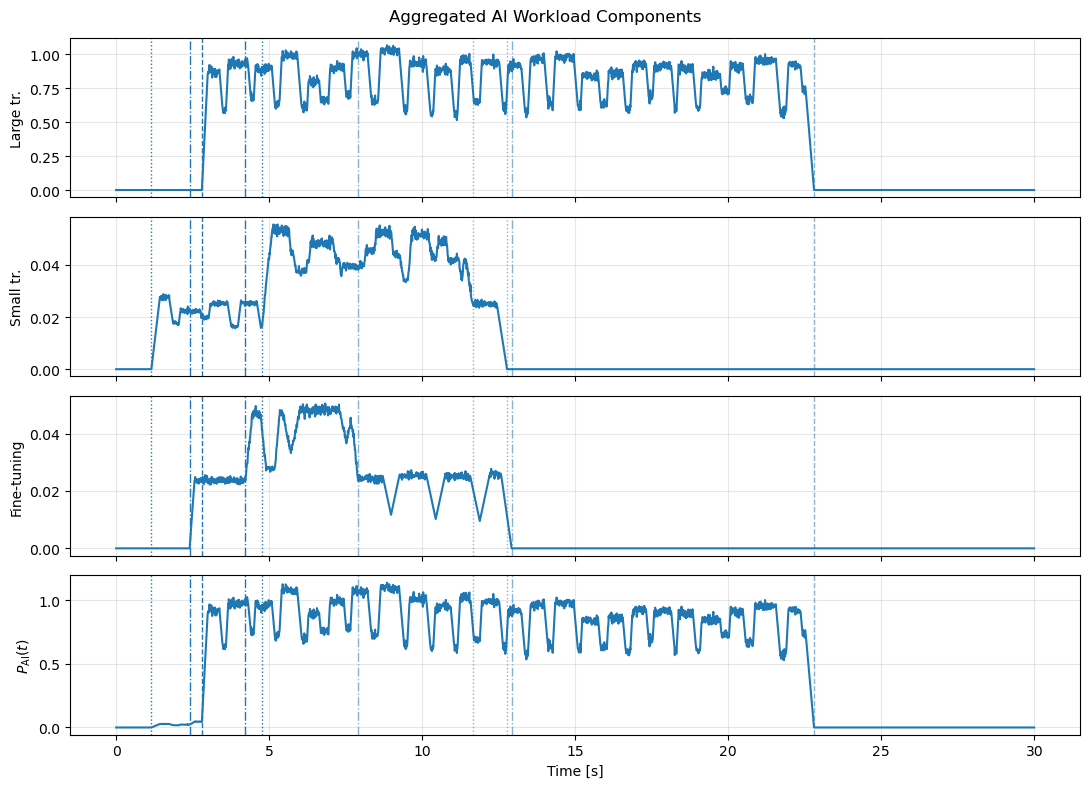

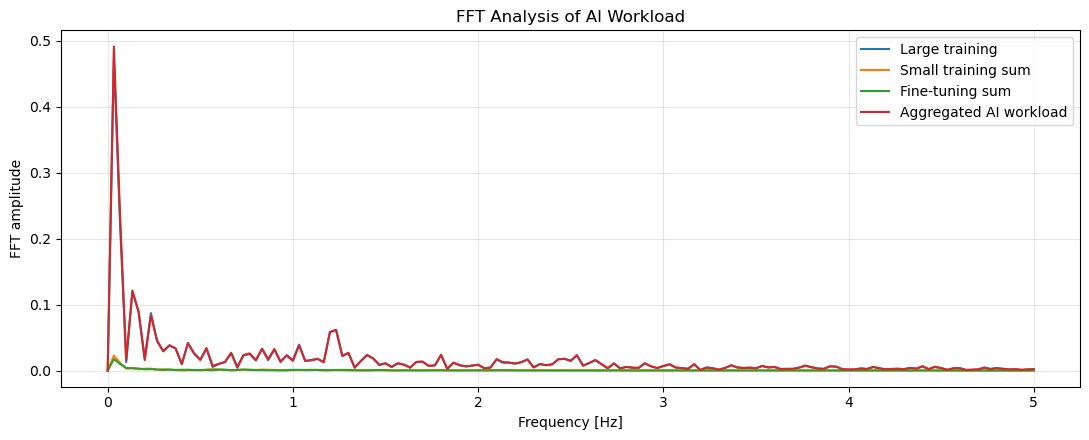

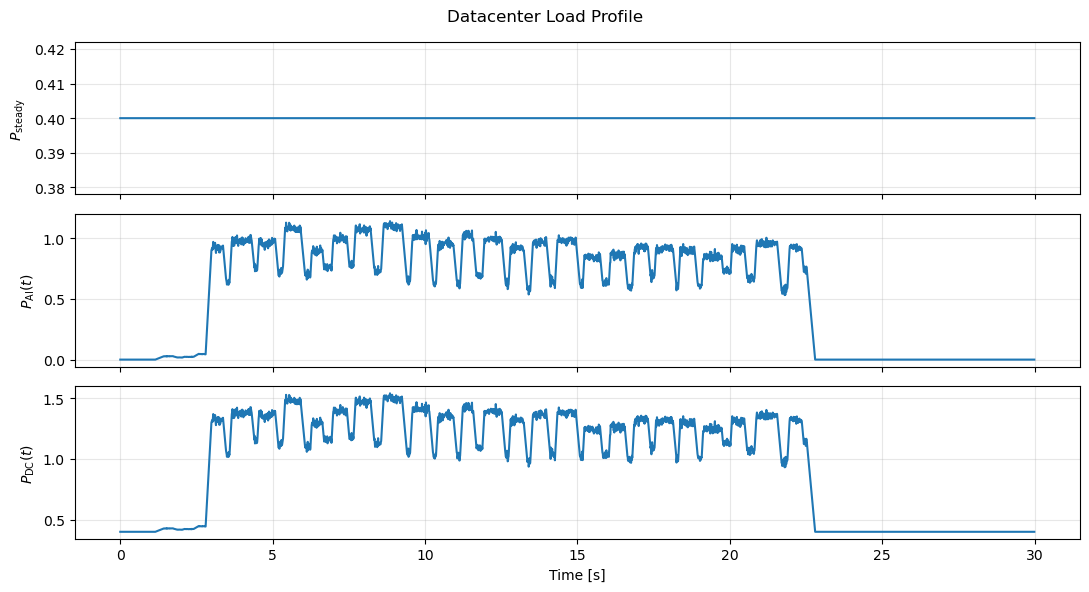

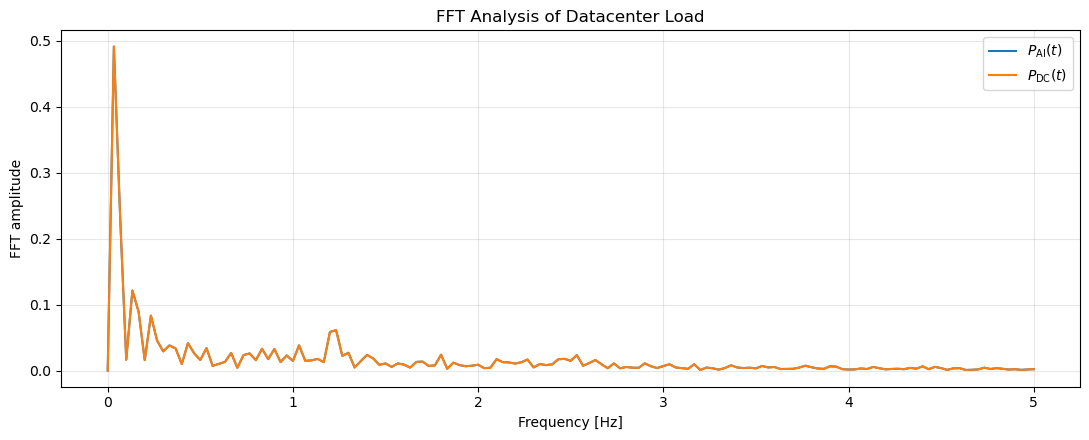

In [5]:
T = 30.0
Fs = 100
seed = 1

# -----------------------------------------------------------------------------
# Scheduling convention
# -----------------------------------------------------------------------------
# Fixed turn-on:
#   "turn_on_mode": "fixed"
#   "turn_on_time": user-specified start time [s]
#
# Random turn-on:
#   "turn_on_mode": "random"
#   "turn_on_range": (lower_bound, upper_bound) [s]
#   -> turn_on_time ~ Uniform(lower_bound, upper_bound), subject to
#      turn_on_time + duration <= T.
#
# duration [s]: total active duration from turn-on until the workload is zero.
# turn_off_time is NOT specified; it is computed as
#   turn_off_time = turn_on_time + duration.
#
# ramp_up/down_ratio [1/s]: turn-on/turn-off boundary ramp-rate limits.
# periodic_ramp_up/down_ratio [1/s]: internal periodic low<->high transition limits.
# All ramp ratios are normalized by the nominal power of each workload.

large_training_schedule = {
    "turn_on_mode": "random",
    "turn_on_range": (0.50, 5.00),
    "duration": 20,          # derived turn-off = 9.00 s
    "ramp_up_ratio": 5.0,
    "ramp_down_ratio": 3.0,
    "periodic_ramp_up_ratio": 5.0,
    "periodic_ramp_down_ratio": 3.0,
}

small_training_schedules = [
    {
        "turn_on_mode": "random",
        "turn_on_range": (0.50, 5.00),
        "duration": 10.50,
        "ramp_up_ratio": 4.0,
        "ramp_down_ratio": 3.0,
        "periodic_ramp_up_ratio": 4.0,
        "periodic_ramp_down_ratio": 3.0,
    },
    {
        "turn_on_mode": "random",
        "turn_on_range": (0.50, 5.00),
        "duration": 8.0,
        "ramp_up_ratio": 5.0,
        "ramp_down_ratio": 3.0,
        "periodic_ramp_up_ratio": 5.0,
        "periodic_ramp_down_ratio": 5.0,
    },
]

finetuning_schedules = [
    {
        "turn_on_mode": "random",
        "turn_on_range": (0.50, 5.00),
        "duration": 5.50,
        "ramp_up_ratio": 6.0,
        "ramp_down_ratio": 4.0,
        "periodic_ramp_up_ratio": 5.0,
        "periodic_ramp_down_ratio": 4.0,
    },
    {
        "turn_on_mode": "random",
        "turn_on_range": (0.50, 5.00),
        "duration": 8.70,
        "ramp_up_ratio": 4.0,
        "ramp_down_ratio": 3.0,
        "periodic_ramp_up_ratio": 2.0,
        "periodic_ramp_down_ratio": 2.0,
    },
]

P_AI, components = aggregated_ai_workload(
    T=T,
    Fs=Fs,
    total_ai_nominal=1.0,
    large_training_ratio=0.90,
    small_training_total_ratio=0.05,
    finetuning_total_ratio=0.05,
    Ntr=2,
    Nft=2,
    large_training_schedule=large_training_schedule,
    small_training_schedules=small_training_schedules,
    finetuning_schedules=finetuning_schedules,
    seed=seed,
    return_components=True,
)

plot_ai_workload_components(
    P_AI=P_AI,
    components=components,
    Fs=Fs,
    show_start_times=True,
    show_turn_off_times=True,
)

plot_ai_workload_fft(P_AI=P_AI, components=components, Fs=Fs, fmax=5.0)

P_DC, dc_components = datacenter_load_profile(
    T=T,
    Fs=Fs,
    datacenter_capacity=1.0,
    steady_component_ratio=0.40,
    fluctuating_component_ratio=0.60,
    P_AI=P_AI,
    components=components,
    seed=seed,
    return_components=True,
)

plot_datacenter_load(P_DC=P_DC, components=dc_components, Fs=Fs)
plot_datacenter_fft(P_DC=P_DC, components=dc_components, Fs=Fs, fmax=5.0)


## No large training workload and large nubmer of small training and fine-tuning workloads
### Can imitate the current datacenter's behavior

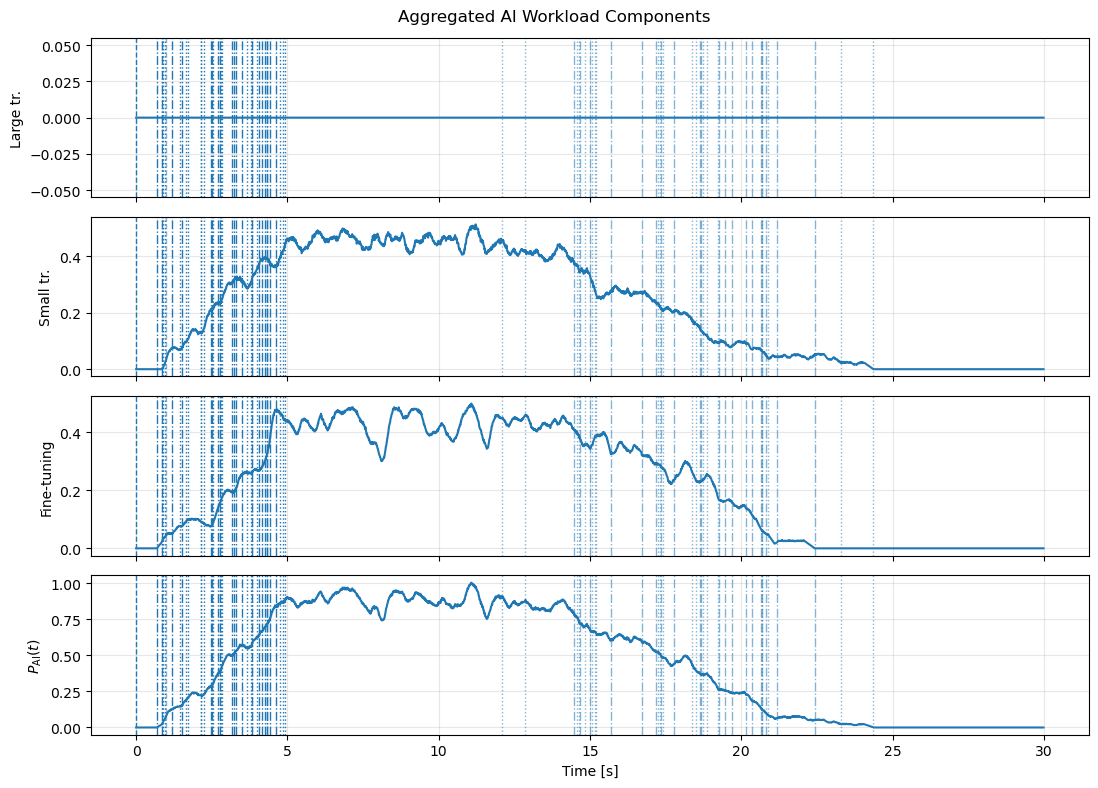

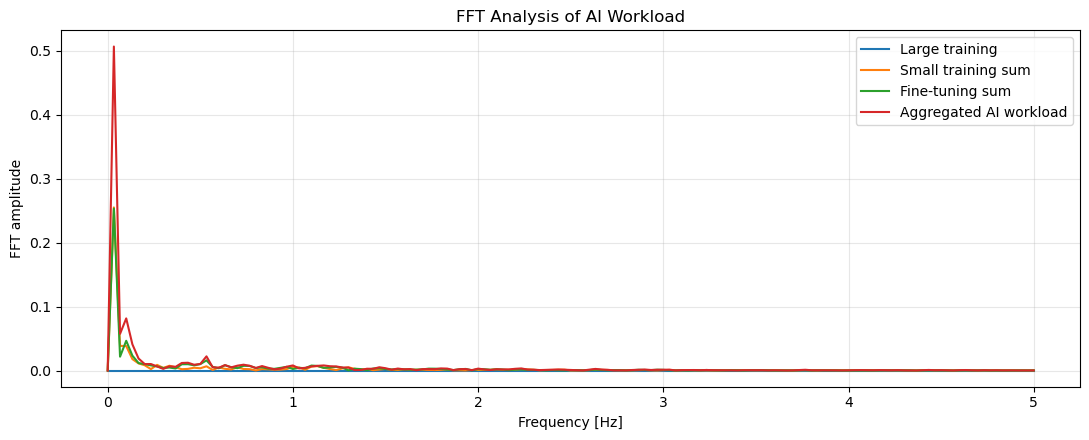

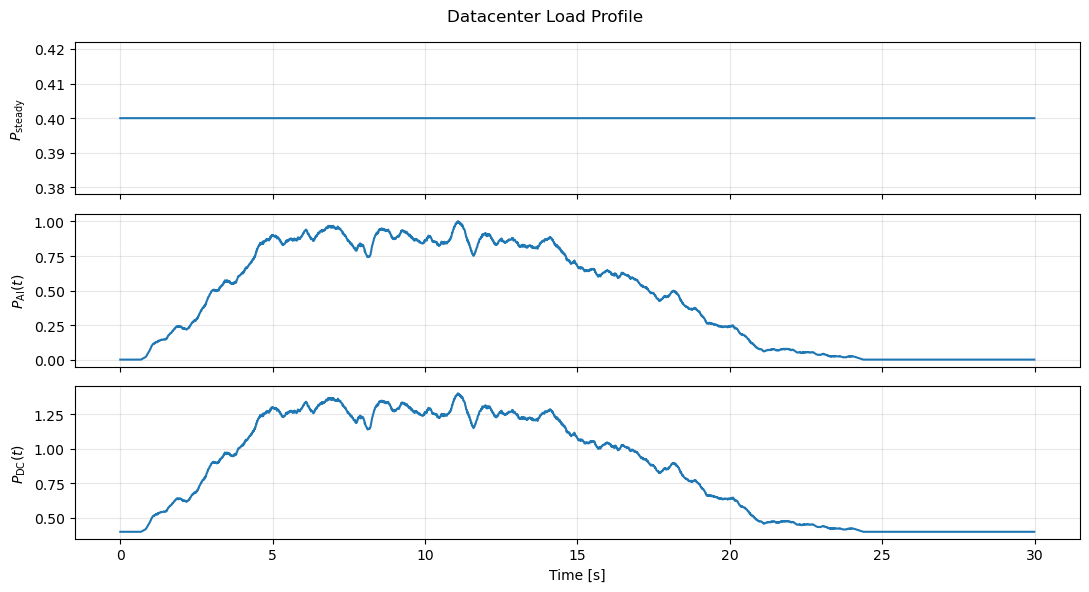

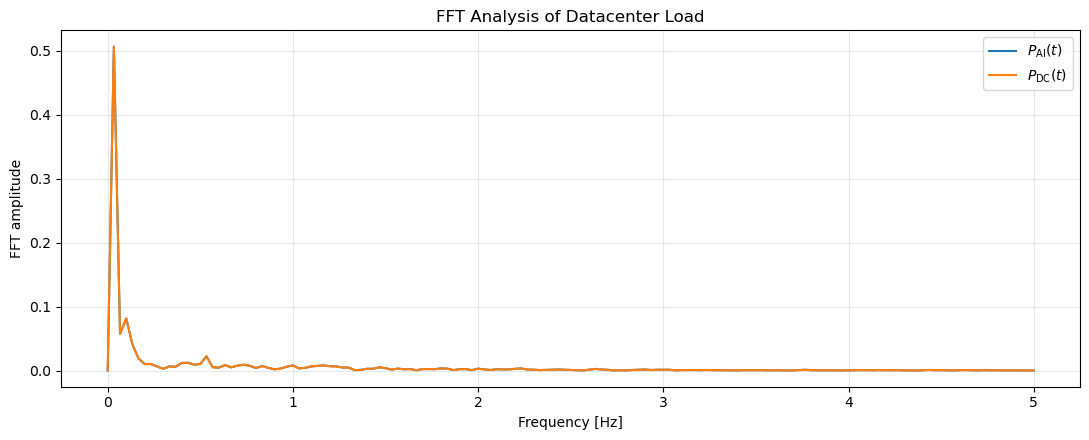

In [10]:
T = 30.0
Fs = 100
seed = 1
Ntr = 20
Nft = 20

# Example: all small-training workloads use random turn-on times, while
# fine-tuning workloads alternate between fixed and random turn-on options.
small_training_schedules = [
    {
        "turn_on_mode": "random",
        "turn_on_range": (0.20, 5.0),
        "duration": round(10+10*np.random.rand(), 3),
        "ramp_up_ratio": 5.0,
        "ramp_down_ratio": 3.0,
        "periodic_ramp_up_ratio": 5.0,
        "periodic_ramp_down_ratio": 3.0,
    }
    for k in range(Ntr)
]

finetuning_schedules = [
    (
        {
            "turn_on_mode": "random",
            "turn_on_range": (0.30, 5.0),
            "duration": round(10+10*np.random.rand(), 3),
            "ramp_up_ratio": 5.0,
            "ramp_down_ratio": 3.0,
            "periodic_ramp_up_ratio": 5.0,
            "periodic_ramp_down_ratio": 3.0,
        }
    )
    for k in range(Nft)
]

P_AI, components = aggregated_ai_workload(
    T=T,
    Fs=Fs,
    total_ai_nominal=1.0,
    large_training_ratio=0.00,
    small_training_total_ratio=0.50,
    finetuning_total_ratio=0.50,
    Ntr=Ntr,
    Nft=Nft,
    # Zero-capacity large-training component: keep a valid but inactive schedule.
    large_training_schedule={
        "turn_on_mode": "fixed",
        "turn_on_time": 0.0,
        "duration": 1.0,
        "ramp_up_ratio": np.inf,
        "ramp_down_ratio": np.inf,
        "periodic_ramp_up_ratio": np.inf,
        "periodic_ramp_down_ratio": np.inf,
    },
    small_training_schedules=small_training_schedules,
    finetuning_schedules=finetuning_schedules,
    seed=seed,
    return_components=True,
)

plot_ai_workload_components(
    P_AI=P_AI,
    components=components,
    Fs=Fs,
    show_start_times=True,
    show_turn_off_times=True,
)

plot_ai_workload_fft(P_AI=P_AI, components=components, Fs=Fs, fmax=5.0)

P_DC, dc_components = datacenter_load_profile(
    T=T,
    Fs=Fs,
    datacenter_capacity=1.0,
    steady_component_ratio=0.40,
    fluctuating_component_ratio=0.60,
    P_AI=P_AI,
    components=components,
    seed=seed,
    return_components=True,
)

plot_datacenter_load(P_DC=P_DC, components=dc_components, Fs=Fs)
plot_datacenter_fft(P_DC=P_DC, components=dc_components, Fs=Fs, fmax=5.0)
